# Klasifikasi Gambar Asli vs AI-Generated menggunakan Swin Transformer Base

Notebook Google Colab untuk fine-tuning `swin_base_patch4_window7_224.ms_in22k_ft_in1k`.

**Fitur utama**
- Dataset ZIP dibaca dari Google Drive dan diekstrak ke penyimpanan lokal runtime Colab (`/content`).
- Dataset gambar diberi label berdasarkan nama folder kelas (Real dan AI-generated).
- Pembagian data stratified 80% train, 10% validation, 10% test.
- Fine-tuning Swin Transformer dengan pretrained ImageNet-22k kemudian fine-tuned ImageNet-1k.
- Checkpoint `last` disimpan setiap akhir epoch; `best` disimpan saat validation loss membaik.
- Jika runtime terputus, jalankan ulang notebook dan aktifkan `RESUME_TRAINING` untuk melanjutkan.
- Semua hasil eksperimen, split CSV, log, checkpoint, model terbaik, grafik, dan evaluasi disimpan di Google Drive.

**Catatan metodologis:** paper referensi menggunakan preprocessing 224×224, Gaussian smoothing, normalisasi intensitas, augmentasi flip/rotasi/brightness, split 80:10:10, AdamW, learning rate 1e-4, cosine annealing, weight decay 1e-5, dropout 0.3, early stopping 5, dan gradient clipping 1.0. Parameter tersebut menjadi titik awal eksperimen, bukan jaminan bahwa konfigurasi terbaik untuk Swin Transformer. Batch size diatur 16 agar lebih realistis untuk Swin-Base di GPU Colab; sesuaikan dengan kapasitas GPU.

## 1. Instalasi dependensi

In [1]:
!pip -q install timm==1.0.15 scikit-learn seaborn pandas matplotlib pillow tqdm

## 2. Hubungkan Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Konfigurasi eksperimen

In [4]:
from pathlib import Path
import os, json, random, shutil, zipfile, re, time, math, copy, gc
import numpy as np
import pandas as pd
from PIL import Image, ImageFile

import timm
import torch
import torch.nn as nn
from torch.optim import AdamW

# ====== UBAH BAGIAN INI ======
ZIP_PATH = "/content/drive/MyDrive/Semester_5/Citra/archive.zip"  # lokasi ZIP dataset di Google Drive
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/Semester_5/Citra/hasil_swin_transformer_ai_real"
EXTRACT_DIR = "/content/dataset_ai_real"                # ekstraksi lokal Colab, bukan ke Drive

MODEL_NAME = "swin_base_patch4_window7_224.ms_in22k_ft_in1k"
SEED = 42
RESUME_TRAINING = True
USE_GAUSSIAN_BLUR = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

# ====== Pengaturan Model & Optimizer ======
# 1. Load model dengan Stochastic Depth (drop_path_rate) untuk mencegah overfitting
model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=2,          # Ubah ke 1 jika memakai BCEWithLogitsLoss
    drop_path_rate=0.2
).to(DEVICE)

# 2. Pisahkan parameter: tanpa weight decay untuk bias, LayerNorm, & relative position bias
no_decay_keywords = ("bias", "norm", "relative_position_bias_table")
head_keywords = ("head",)

backbone_decay, backbone_no_decay = [], []
head_decay, head_no_decay = [], []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    is_no_decay = any(k in name for k in no_decay_keywords)
    is_head = any(k in name for k in head_keywords)

    if is_head:
        (head_no_decay if is_no_decay else head_decay).append(param)
    else:
        (backbone_no_decay if is_no_decay else backbone_decay).append(param)

# 3. Inisialisasi Optimizer AdamW
base_lr = 2e-5
head_lr = 1e-4
weight_decay = 0.02

optimizer = AdamW(
    [
        {"params": backbone_decay, "lr": base_lr, "weight_decay": weight_decay},
        {"params": backbone_no_decay, "lr": base_lr, "weight_decay": 0.0},
        {"params": head_decay, "lr": head_lr, "weight_decay": weight_decay},
        {"params": head_no_decay, "lr": head_lr, "weight_decay": 0.0},
    ],
    betas=(0.9, 0.999),
    eps=1e-8
)

epochs = 5
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

# Folder yang mengandung nama berikut akan dikenali sebagai kelas.
CLASS_FOLDER_MAP = {
    "Real": ["real"],
    "AI-generated": ["fake"]
}

os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
OUTPUT_DIR = Path(DRIVE_OUTPUT_DIR)
EXTRACT_DIR = Path(EXTRACT_DIR)

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("ZIP:", ZIP_PATH)
print("Output:", OUTPUT_DIR)
print("Model:", MODEL_NAME)

Device: cuda
GPU: Tesla T4
ZIP: /content/drive/MyDrive/Semester_5/Citra/archive.zip
Output: /content/drive/MyDrive/Semester_5/Citra/hasil_swin_transformer_ai_real
Model: swin_base_patch4_window7_224.ms_in22k_ft_in1k


## 4. Ekstrak ZIP ke penyimpanan lokal Colab

In [5]:
assert os.path.isfile(ZIP_PATH), f"File ZIP tidak ditemukan: {ZIP_PATH}"

# Ekstrak hanya jika belum pernah diekstrak. Hapus folder lokal jika ingin ekstraksi ulang.
extract_marker = EXTRACT_DIR / ".extraction_complete"
if not extract_marker.exists():
    if EXTRACT_DIR.exists():
        shutil.rmtree(EXTRACT_DIR)
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)
    extract_marker.write_text("ok")
    print("Ekstraksi selesai.")
else:
    print("Folder hasil ekstraksi sudah tersedia; ekstraksi dilewati.")

print("Isi folder:", [p.name for p in list(EXTRACT_DIR.iterdir())[:20]])

Ekstraksi selesai.
Isi folder: ['test', '.extraction_complete', 'train']


## 5. Identifikasi gambar dan label kelas

Notebook mencari file gambar secara rekursif. Label ditentukan dari nama folder induk yang cocok dengan `CLASS_FOLDER_MAP`. Struktur umum yang didukung misalnya:

```text
dataset/
  train/
    AI-generated/
    Real/
  test/
    AI-generated/
    Real/
```

atau:

```text
dataset/
  AI-generated/
  Real/
```

Folder `train`, `test`, dan `valid` tidak dianggap sebagai label. Jika nama folder kelas dataset berbeda, tambahkan nama folder tersebut pada `CLASS_FOLDER_MAP` di bagian konfigurasi.

In [6]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Normalisasi nama folder untuk pencocokan yang lebih toleran.
def norm_name(s):
    return re.sub(r"[^a-z0-9]+", "", str(s).lower())

alias_to_label = {}
for label, aliases in CLASS_FOLDER_MAP.items():
    for alias in aliases:
        alias_to_label[norm_name(alias)] = label

records = []
unmatched = []
for fp in EXTRACT_DIR.rglob("*"):
    if fp.is_file() and fp.suffix.lower() in IMAGE_EXTS:
        label = None
        # Periksa semua folder induk, dari folder terdekat ke terluar.
        for parent in fp.parents:
            if parent == EXTRACT_DIR.parent:
                break
            candidate = alias_to_label.get(norm_name(parent.name))
            if candidate is not None:
                label = candidate
                break
            if parent == EXTRACT_DIR:
                break
        if label is None:
            unmatched.append(str(fp))
        else:
            records.append({"path": str(fp), "label": label})

df = pd.DataFrame(records)
print("Jumlah gambar terlabel:", len(df))
print("Jumlah gambar tanpa label folder:", len(unmatched))
if len(unmatched):
    print("Contoh folder yang belum dikenali:", sorted({Path(x).parent.name for x in unmatched})[:30])

assert len(df) > 0, (
    "Tidak ada gambar yang berhasil diberi label. Periksa struktur folder ZIP "
    "dan sesuaikan CLASS_FOLDER_MAP."
)
assert set(df["label"].unique()) == {"Real", "AI-generated"}, (
    f"Harus ditemukan dua kelas Real dan AI-generated. Ditemukan: {df['label'].value_counts().to_dict()}"
)

print(df["label"].value_counts())
display(df.sample(min(5, len(df)), random_state=SEED))

Jumlah gambar terlabel: 60000
Jumlah gambar tanpa label folder: 0
label
AI-generated    30000
Real            30000
Name: count, dtype: int64


,path,label
12628,/content/dataset_ai_real/train/fake/23807.png,AI-generated
37730,/content/dataset_ai_real/train/real/11741.jpg,Real
39991,/content/dataset_ai_real/train/real/6132.jpg,Real
8525,/content/dataset_ai_real/train/fake/18501.png,AI-generated
8279,/content/dataset_ai_real/train/fake/4194.jpg,AI-generated


In [7]:
import hashlib

def calculate_sha256(file_path):
    sha256 = hashlib.sha256()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)
    return sha256.hexdigest()

df["sha256"] = df["path"].apply(calculate_sha256)

# Cari gambar identik yang ternyata memiliki label berbeda.
conflicting_hashes = (
    df.groupby("sha256")["label"].nunique()
      .loc[lambda x: x > 1].index
)

conflicting = df[df["sha256"].isin(conflicting_hashes)].copy()
conflicting["duplicate_status"] = "same_image_different_label"

# Hapus seluruh gambar yang sama tetapi memiliki label berbeda.
df = df[~df["sha256"].isin(conflicting_hashes)].copy()

# Untuk duplikat dengan label sama, pertahankan satu file saja.
duplicate_mask = df.duplicated(subset="sha256", keep="first")
duplicates = df[duplicate_mask].copy()
duplicates["duplicate_status"] = "exact_duplicate"

duplicate_report = pd.concat([conflicting, duplicates], ignore_index=True)
duplicate_report.to_csv(OUTPUT_DIR / "duplicate_report.csv", index=False)

df = df.drop_duplicates(subset="sha256", keep="first")
df = df.drop(columns=["sha256"]).reset_index(drop=True)

print("Jumlah gambar setelah deduplikasi:", len(df))
print("Duplikat identik yang dihapus:", len(duplicates))
print("Gambar dengan konflik label yang dihapus:", len(conflicting))
print("Distribusi kelas setelah deduplikasi:")
print(df["label"].value_counts())

Jumlah gambar setelah deduplikasi: 59959
Duplikat identik yang dihapus: 41
Gambar dengan konflik label yang dihapus: 0
Distribusi kelas setelah deduplikasi:
label
Real            29994
AI-generated    29965
Name: count, dtype: int64


## 6. Pemeriksaan sampel gambar

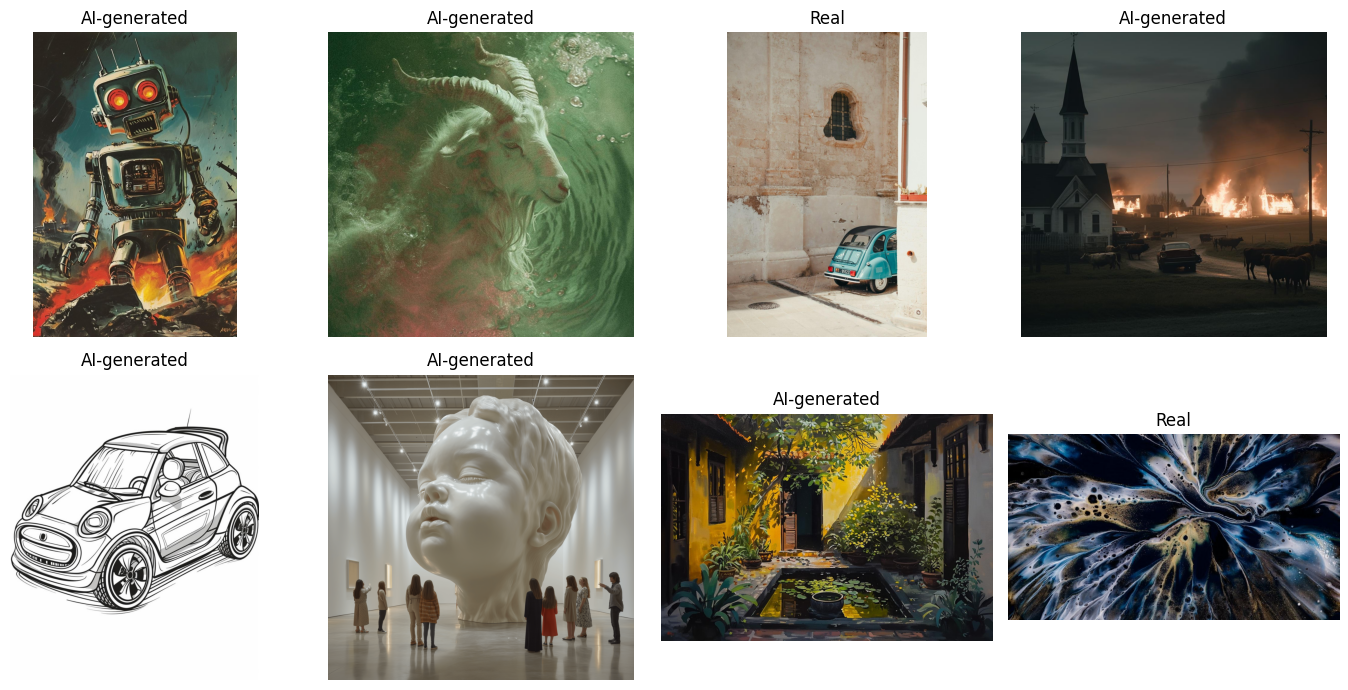

In [8]:
import matplotlib.pyplot as plt

sample_df = df.sample(min(8, len(df)), random_state=SEED).reset_index(drop=True)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    try:
        img = Image.open(row["path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(row["label"])
    except Exception as e:
        ax.set_title("Gagal dibaca")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Pembagian train, validation, dan test (stratified 80:10:10)

Pembagian dilakukan per gambar dengan seed tetap. File `data_split.csv` disimpan di Drive. Ketika notebook dijalankan ulang, split yang sudah tersimpan akan digunakan kembali agar checkpoint tidak dipasangkan dengan pembagian data yang berbeda.

**Peringatan penelitian:** random split dapat menghasilkan kebocoran bila ada gambar duplikat/varian dari sumber yang sama pada subset berbeda. Untuk evaluasi generalisasi yang lebih kuat, pertimbangkan deduplikasi dan/atau pemisahan berdasarkan sumber/generator sebelum eksperimen final.

In [9]:
from sklearn.model_selection import train_test_split

SPLIT_CSV = OUTPUT_DIR / "data_split.csv"
if SPLIT_CSV.exists():
    split_df = pd.read_csv(SPLIT_CSV)
    print("Menggunakan split yang sudah tersimpan:", SPLIT_CSV)
else:
    train_df, temp_df = train_test_split(
        df, test_size=0.20, random_state=SEED, stratify=df["label"]
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
    )
    train_df = train_df.assign(split="train")
    val_df = val_df.assign(split="val")
    test_df = test_df.assign(split="test")
    split_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
    split_df.to_csv(SPLIT_CSV, index=False)

# Validasi file pada split
missing = [p for p in split_df["path"].tolist() if not os.path.isfile(p)]
assert not missing, f"Ada {len(missing)} path yang tidak ditemukan. Dataset lokal mungkin perlu diekstrak ulang."

train_df = split_df[split_df["split"] == "train"].reset_index(drop=True)
val_df = split_df[split_df["split"] == "val"].reset_index(drop=True)
test_df = split_df[split_df["split"] == "test"].reset_index(drop=True)

print("Jumlah data:")
for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"\n{name}: {len(part)} ({len(part)/len(split_df):.1%})")
    print(part["label"].value_counts())

Jumlah data:

Train: 47967 (80.0%)
label
Real            23995
AI-generated    23972
Name: count, dtype: int64

Validation: 5996 (10.0%)
label
Real            3000
AI-generated    2996
Name: count, dtype: int64

Test: 5996 (10.0%)
label
Real            2999
AI-generated    2997
Name: count, dtype: int64


## 8. Setup library, seed, dan preprocessing

In [10]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm
from timm.data import resolve_model_data_config
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, roc_auc_score
import io
import random
import numpy as np
from PIL import Image

# Definisikan parameter gambar yang sebelumnya dihapus dari konfigurasi agar tidak error
IMAGE_SIZE = 224
BATCH_SIZE = 32  # Menyesuaikan rekomendasi metodologi untuk Swin-Base di Colab
NUM_WORKERS = 2

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Menggunakan model yang sudah diinisialisasi di sel konfigurasi untuk mengambil normalisasi
data_config = resolve_model_data_config(model)
PRETRAINED_MEAN = data_config["mean"]
PRETRAINED_STD = data_config["std"]

# Fungsi helper untuk simulasi JPEG compression pada PIL Image
class RandomJPEGCompression:
    def __init__(self, quality_range=(30, 95)):
        self.quality_range = quality_range

    def __call__(self, img):
        quality = random.randint(self.quality_range[0], self.quality_range[1])
        output = io.BytesIO()
        img.save(output, format="JPEG", quality=quality)
        output.seek(0)
        return Image.open(output).convert("RGB")

# 1. Transformasi Data Latih (Train Transform)
train_transform_list = [
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
]

# Gaussian Blur dengan probabilitas p = 0.1
if USE_GAUSSIAN_BLUR:
    train_transform_list.append(
        transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=0.1)
    )

# Kombinasi JPEG Compression dengan probabilitas p = 0.2 (di rentang 0.2 - 0.5)
train_transform_list.append(
    transforms.RandomApply([RandomJPEGCompression((30, 95))], p=0.2)
)

train_transform_list += [
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=PRETRAINED_MEAN, std=PRETRAINED_STD),
]
train_transform = transforms.Compose(train_transform_list)

# 2. Transformasi Data Validasi & Uji (Eval Transform) - Selalu TANPA Gaussian Blur & JPEG Compression
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=PRETRAINED_MEAN, std=PRETRAINED_STD),
])

print("Mean:", PRETRAINED_MEAN)
print("Std:", PRETRAINED_STD)

Device: cuda
GPU: Tesla T4
Mean: (0.485, 0.456, 0.406)
Std: (0.229, 0.224, 0.225)


## 9. Dataset dan DataLoader

In [11]:
CLASS_NAMES = ["Real", "AI-generated"]
LABEL_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
ID_TO_LABEL = {idx: name for name, idx in LABEL_TO_ID.items()}

class ImageBinaryDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row["path"]) as im:
            image = im.convert("RGB")
        image = self.transform(image)
        label = LABEL_TO_ID[row["label"]]
        return image, label

train_ds = ImageBinaryDataset(train_df, train_transform)
val_ds = ImageBinaryDataset(val_df, eval_transform)
test_ds = ImageBinaryDataset(test_df, eval_transform)

pin_memory = DEVICE.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin_memory)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin_memory)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin_memory)

print("Batch train:", len(train_loader))

Batch train: 1499


## 10. Inisialisasi Swin Transformer

In [12]:
# Menghubungkan variabel optimizer dan scheduler baru dengan sisa kode
# Agar model, optimizer, scheduler, criterion, dan scaler yang telah didefinisikan di sel 3 (Konfigurasi) tidak tertimpa kembali.

EPOCHS = epochs
USE_AMP = DEVICE.type == "cuda"

# Buat scheduler di sini agar len(train_loader) pasti membaca DataLoader terbaru
steps_per_epoch = len(train_loader)  # Contoh: 48.000 / 64 = 750 steps
total_steps = epochs * steps_per_epoch
warmup_steps = 1 * steps_per_epoch   # 1 epoch pertama untuk warmup
min_lr_ratio = 0.05                  # Turun hingga 5% dari base_lr (1e-6)

def lr_lambda(current_step):
    if current_step < warmup_steps:
        return float(current_step + 1) / float(max(1, warmup_steps))
    progress = float(current_step - warmup_steps) / float(max(1, total_steps - warmup_steps))
    cosine_decay = 0.5 * (1.0 + math.cos(math.pi * progress))
    return min_lr_ratio + (1.0 - min_lr_ratio) * cosine_decay

scheduler = LambdaLR(optimizer, lr_lambda)

# Hitung parameter model
num_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameter: {num_params:,}")
print(f"Trainable parameter: {trainable_params:,}")
print("Menggunakan optimizer, scheduler, dan kriteria kustom yang baru saja Anda atur di sel Konfigurasi.")

Total parameter: 86,745,274
Trainable parameter: 86,745,274
Menggunakan optimizer, scheduler, dan kriteria kustom yang baru saja Anda atur di sel Konfigurasi.


## 11. Fungsi training, evaluasi, dan checkpoint

Checkpoint berisi bobot model, optimizer, scheduler, GradScaler, epoch, best validation loss, dan riwayat metrik. Penyimpanan dilakukan setelah setiap epoch selesai. Jika runtime mati di tengah epoch, proses akan dilanjutkan dari checkpoint akhir epoch sebelumnya (epoch yang sedang berjalan perlu diulang).

In [13]:
import csv
from tqdm.auto import tqdm

LAST_CKPT = OUTPUT_DIR / "checkpoint_last.pth"
BEST_CKPT = OUTPUT_DIR / "checkpoint_best.pth"
HISTORY_CSV = OUTPUT_DIR / "training_history.csv"
CONFIG_JSON = OUTPUT_DIR / "experiment_config.json"

experiment_config = {
    "model_name": "swin_base_patch4_window7_224.ms_in22k_ft_in1k",
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": base_lr,
    "weight_decay": weight_decay,
    "seed": SEED,
    "class_names": CLASS_NAMES,
    "pretrained_mean": PRETRAINED_MEAN,
    "pretrained_std": PRETRAINED_STD,
    "gaussian_blur": USE_GAUSSIAN_BLUR,
    "split": "80/10/10 stratified",
}
with open(CONFIG_JSON, "w") as f:
    json.dump(experiment_config, f, indent=2)

def run_epoch(loader, training=False):
    model.train(training)
    total_loss, total_correct, total_count = 0.0, 0, 0
    all_labels, all_preds, all_probs = [], [], []

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        loop = tqdm(loader, leave=False)
        for images, labels in loop:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16,
                                enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

                scale_before = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                # Hanya majukan scheduler jika optimizer benar-benar melakukan update bobot
                if scaler.get_scale() >= scale_before:
                    scheduler.step()

            probs = torch.softmax(logits.detach().float(), dim=1)
            preds = torch.argmax(probs, dim=1)

            bs = labels.size(0)
            total_loss += loss.item() * bs
            total_correct += (preds == labels).sum().item()
            total_count += bs
            all_labels.extend(labels.detach().cpu().numpy().tolist())
            all_preds.extend(preds.cpu().numpy().tolist())
            all_probs.extend(probs[:, 1].cpu().numpy().tolist())

            loop.set_postfix(loss=f"{loss.item():.4f}")

    avg_loss = total_loss / max(total_count, 1)
    acc = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="binary", zero_division=0
    )
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except ValueError:
        auc = float("nan")

    return {
        "loss": avg_loss, "accuracy": acc, "precision": precision,
        "recall": recall, "f1": f1, "auc": auc,
        "labels": all_labels, "preds": all_preds, "probs": all_probs
    }

def save_checkpoint(path, epoch, best_val_loss, epochs_without_improvement, history):
    state = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_loss": best_val_loss,
        "epochs_without_improvement": epochs_without_improvement,
        "history": history,
        "config": experiment_config,
        "class_to_idx": LABEL_TO_ID,
    }
    temp_path = str(path) + ".tmp"
    torch.save(state, temp_path)
    os.replace(temp_path, path)

## 12. Mulai atau lanjutkan training

In [ ]:
start_epoch = 0
best_val_loss = float("inf")
epochs_without_improvement = 0
history = []
PATIENCE = 2  # Menambahkan kembali parameter patience

if RESUME_TRAINING and LAST_CKPT.exists():
    print("Checkpoint ditemukan. Memuat state training...")
    checkpoint = torch.load(LAST_CKPT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    start_epoch = int(checkpoint["epoch"])
    best_val_loss = float(checkpoint["best_val_loss"])
    epochs_without_improvement = int(checkpoint.get("epochs_without_improvement", 0))
    history = checkpoint.get("history", [])
    print(f"Melanjutkan dari epoch {start_epoch + 1}; best val loss={best_val_loss:.5f}")
else:
    print("Memulai training dari awal.")

for epoch in range(start_epoch, EPOCHS):
    epoch_start = time.time()
    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    # Scheduler di-update per step di dalam run_epoch untuk train_loader
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    row = {
        "epoch": epoch + 1,
        "lr": optimizer.param_groups[0]["lr"],
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_precision": train_metrics["precision"],
        "train_recall": train_metrics["recall"],
        "train_f1": train_metrics["f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "val_auc": val_metrics["auc"],
        "seconds": time.time() - epoch_start,
    }
    history.append(row)
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    improved = val_metrics["loss"] < best_val_loss
    if improved:
        best_val_loss = val_metrics["loss"]
        epochs_without_improvement = 0
        save_checkpoint(BEST_CKPT, epoch + 1, best_val_loss, epochs_without_improvement, history)
        print("Best checkpoint diperbarui.")
    else:
        epochs_without_improvement += 1

    save_checkpoint(LAST_CKPT, epoch + 1, best_val_loss, epochs_without_improvement, history)

    print(
        f"Train loss={train_metrics['loss']:.4f} acc={train_metrics['accuracy']:.4f} | "
        f"Val loss={val_metrics['loss']:.4f} acc={val_metrics['accuracy']:.4f} "
        f"F1={val_metrics['f1']:.4f} AUC={val_metrics['auc']:.4f}"
    )
    print(f"Durasi epoch: {row['seconds']/60:.1f} menit")

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: validation loss tidak membaik selama {PATIENCE} epoch.")
        break

print("Training loop selesai.")
print("Checkpoint last:", LAST_CKPT)
print("Checkpoint best:", BEST_CKPT)

Memulai training dari awal.

Epoch 1/5


  0%|          | 0/1499 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (121554000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (96012000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (96000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-p

  0%|          | 0/188 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Best checkpoint diperbarui.
Train loss=0.3617 acc=0.8569 | Val loss=0.1914 acc=0.9625 F1=0.9623 AUC=0.9947
Durasi epoch: 78.2 menit

Epoch 2/5


  0%|          | 0/1499 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (161087488 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (98058240 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


## 13. Grafik riwayat training

In [ ]:
history_df = pd.read_csv(HISTORY_CSV)
display(history_df.tail())

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training dan Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_accuracy"], label="Train accuracy")
plt.plot(history_df["epoch"], history_df["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training dan Validation Accuracy")
plt.legend()
plt.grid(True)
plt.savefig(OUTPUT_DIR / "accuracy_curve.png", dpi=200, bbox_inches="tight")
plt.show()

## 14. Evaluasi final pada test set menggunakan checkpoint terbaik

In [ ]:
assert BEST_CKPT.exists(), "Best checkpoint tidak ditemukan. Pastikan training sudah berjalan."
best_state = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
model.load_state_dict(best_state["model_state_dict"])

test_metrics = run_epoch(test_loader, training=False)
y_true = test_metrics["labels"]
y_pred = test_metrics["preds"]
y_prob = test_metrics["probs"]

print("TEST METRICS")
for key in ["loss", "accuracy", "precision", "recall", "f1", "auc"]:
    print(f"{key}: {test_metrics[key]:.5f}")

report = classification_report(
    y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0
)
print("\nClassification report:\n", report)

with open(OUTPUT_DIR / "classification_report.txt", "w") as f:
    f.write(report)

metrics_to_save = {k: float(test_metrics[k]) for k in
                   ["loss", "accuracy", "precision", "recall", "f1", "auc"]}
with open(OUTPUT_DIR / "test_metrics.json", "w") as f:
    json.dump(metrics_to_save, f, indent=2)

## 15. Confusion matrix dan hasil prediksi

In [ ]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
import seaborn as sns
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix - Test Set")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

pred_df = test_df.reset_index(drop=True).copy()
pred_df["true_label"] = y_true
pred_df["predicted_label"] = [ID_TO_LABEL[int(x)] for x in y_pred]
pred_df["probability_ai_generated"] = y_prob
pred_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

## 16. Simpan model terbaik untuk inferensi

File `.pth` checkpoint menyimpan state training lengkap. Bagian ini juga menyimpan bobot model terbaik saja agar lebih mudah digunakan kembali untuk inferensi.

In [ ]:
torch.save(model.state_dict(), OUTPUT_DIR / "swin_base_best_weights.pth")

model_info = {
    "model_name": MODEL_NAME,
    "image_size": IMAGE_SIZE,
    "class_names": CLASS_NAMES,
    "label_to_id": LABEL_TO_ID,
    "mean": PRETRAINED_MEAN,
    "std": PRETRAINED_STD,
}
with open(OUTPUT_DIR / "model_inference_config.json", "w") as f:
    json.dump(model_info, f, indent=2)

print("Semua hasil disimpan di:", OUTPUT_DIR)
print("Isi folder hasil:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, f"({p.stat().st_size/1024/1024:.2f} MB)")

## 17. Contoh inferensi satu gambar

Ubah `IMAGE_TO_PREDICT` ke lokasi gambar yang ingin diuji. Contoh ini menggunakan model terbaik yang sudah dimuat.

In [ ]:
IMAGE_TO_PREDICT = ""  # contoh: "/content/contoh_gambar.jpg"

if IMAGE_TO_PREDICT and os.path.isfile(IMAGE_TO_PREDICT):
    infer_img = Image.open(IMAGE_TO_PREDICT).convert("RGB")
    x = eval_transform(infer_img).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
    pred_idx = int(np.argmax(probs))
    print("Prediksi:", ID_TO_LABEL[pred_idx])
    print({ID_TO_LABEL[i]: float(probs[i]) for i in range(len(CLASS_NAMES))})
    plt.imshow(infer_img)
    plt.axis("off")
    plt.show()
else:
    print("Isi IMAGE_TO_PREDICT jika ingin menguji satu gambar.")

## Catatan penggunaan dan metodologi

1. **Resume setelah runtime terputus:** mount Drive, jalankan sel instalasi, mount Drive, konfigurasi dengan path ZIP yang sama dan `RESUME_TRAINING=True`, lalu jalankan sel berikutnya berurutan. Karena folder ekstraksi berada di `/content`, dataset akan diekstrak ulang bila runtime Colab sudah benar-benar di-reset. Checkpoint dan split CSV tetap berada di Drive.
2. **Jangan mengubah konfigurasi penting saat resume** (model, batch size, optimizer, learning rate, jumlah epoch, class mapping, dan split). Bila ingin eksperimen baru, gunakan folder output baru atau hapus checkpoint lama.
3. **Checkpoint dibuat tiap akhir epoch**, bukan setiap batch. Jika runtime terputus di tengah epoch, epoch tersebut akan diulang dari awal.
4. Gaussian blur memakai kernel 3 dan sigma 0.1–1.0 sebagai pilihan implementasi. Paper tidak melaporkan nilai kernel/sigma secara rinci; tuliskan parameter ini sebagai konfigurasi penelitian Anda sendiri.
5. Normalisasi menggunakan mean dan std dari konfigurasi pretrained Swin, bukan angka yang diasumsikan sama dengan paper.
6. Model Swin-Base memiliki kebutuhan VRAM yang cukup besar. Jika CUDA out-of-memory, turunkan `BATCH_SIZE` menjadi 8 atau 4, kemudian mulai eksperimen baru atau pastikan konfigurasi checkpoint konsisten.
7. Akurasi test bukan bukti generalisasi ke semua generator AI. Untuk klaim yang lebih kuat, uji juga pada dataset eksternal atau pisahkan sumber/generator saat pembagian data.